# TA-06: Prediksi Churn Pelanggan Telekomunikasi dengan Random Forest

Notebook ini berisi semua tahapan eksperimen untuk studi kasus **Telco Customer Churn**:

1. Preprocessing data
2. Looping eksperimen Skenario A (jumlah pohon) dan Skenario B (kedalaman pohon)
3. Visualisasi grafik hasil eksperimen
4. Visualisasi *feature importance*

Aplikasi webnya (ChurnForest) memakai konfigurasi dan seed yang sama, jadi angka di sini harus sama dengan angka di web dan laporan.

**Cara menjalankan:** taruh file CSV dataset di folder `data/` (atau di folder yang sama dengan notebook ini), lalu pilih *Run All*. Di Google Colab, upload dulu filenya.

## 1. Import library dan konfigurasi

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    f1_score, recall_score, roc_auc_score, roc_curve,
)
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
TEST_SIZE = 0.2
CV_FOLDS = 5
N_ESTIMATORS_GRID = [10, 50, 100, 200, 500]   # Skenario A
MAX_DEPTH_GRID = [3, 5, 10, 20, None]         # Skenario B
SELECTION_TOLERANCE = 0.005                   # toleransi F1 untuk memilih model yang paling sederhana
NUMERIC = ["tenure", "MonthlyCharges", "TotalCharges"]

BLUE, RED, INK = "#2f5bff", "#ff4d6d", "#111111"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.25, "figure.dpi": 110, "font.size": 10})

## 2. Preprocessing

Langkah-langkahnya:

- Membaca data dan melihat bentuknya.
- Kolom `TotalCharges` ada 11 baris yang kosong. Semuanya milik pelanggan baru dengan `tenure` 0, jadi nilainya diisi 0.
- Kolom `SeniorCitizen` (0 dan 1) diubah jadi `No` dan `Yes` supaya diperlakukan sebagai kategori.
- Kolom `customerID` dibuang karena hanya pengenal, bukan fitur.
- Fitur kategorikal diubah dengan *One-Hot Encoding*, fitur numerik dibiarkan apa adanya (pohon tidak butuh normalisasi).
- Data dibagi 80:20 secara *stratified* supaya proporsi churn di data latih dan uji sama.

In [2]:
nama_file = "WA_Fn-UseC_-Telco-Customer-Churn.csv"
kandidat = [Path("data") / nama_file, Path(nama_file), Path("..") / "data" / nama_file]
lokasi = next((p for p in kandidat if p.exists()), None)
assert lokasi is not None, f"File {nama_file} tidak ditemukan. Taruh di folder data/ atau folder notebook ini."

df = pd.read_csv(lokasi)
print("Ukuran data:", df.shape)
df.head()

Ukuran data: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
total = pd.to_numeric(df["TotalCharges"], errors="coerce")
kosong = total.isna()
print("TotalCharges kosong:", int(kosong.sum()), "baris")
print("Semua kosong milik pelanggan tenure 0:", bool((df.loc[kosong, "tenure"] == 0).all()))

df["TotalCharges"] = total.fillna(0.0)
df["SeniorCitizen"] = df["SeniorCitizen"].map({0: "No", 1: "Yes"})
df = df.drop(columns=["customerID"])

X = df.drop(columns=["Churn"])
y = (df["Churn"] == "Yes").astype(int)
kategorikal = [c for c in X.columns if c not in NUMERIC]
print("Jumlah fitur:", X.shape[1], "| kategorikal:", len(kategorikal), "| numerik:", len(NUMERIC))

TotalCharges kosong: 11 baris
Semua kosong milik pelanggan tenure 0: True
Jumlah fitur: 19 | kategorikal: 16 | numerik: 3


Churn
Bertahan    5174
Churn       1869
Tingkat churn: 26.5%


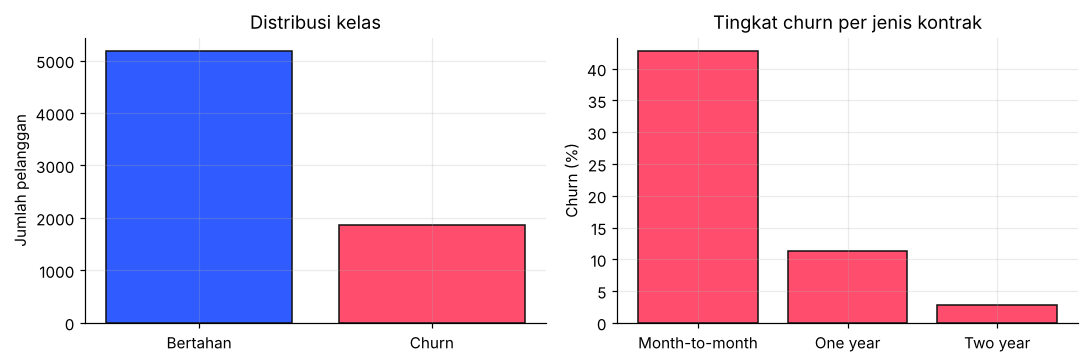

In [4]:
jumlah = y.value_counts().rename({0: "Bertahan", 1: "Churn"})
print(jumlah.to_string())
print(f"Tingkat churn: {y.mean():.1%}")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].bar(jumlah.index, jumlah.values, color=[BLUE, RED], edgecolor=INK)
ax[0].set_title("Distribusi kelas")
ax[0].set_ylabel("Jumlah pelanggan")

laju = df.groupby("Contract")["Churn"].apply(lambda s: (s == "Yes").mean()).sort_values(ascending=False)
ax[1].bar(laju.index, laju.values * 100, color=RED, edgecolor=INK)
ax[1].set_title("Tingkat churn per jenis kontrak")
ax[1].set_ylabel("Churn (%)")
plt.tight_layout()
plt.show()

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_STATE
)
print("Data latih:", len(X_train), "| data uji:", len(X_test))
print(f"Churn di data latih: {y_train.mean():.1%} | di data uji: {y_test.mean():.1%}")


def buat_model(n_estimators, max_depth):
    encoder = ColumnTransformer(
        [("cat", OneHotEncoder(drop="if_binary", handle_unknown="ignore", sparse_output=False), kategorikal)],
        remainder="passthrough",
        verbose_feature_names_out=False,
    )
    forest = RandomForestClassifier(
        n_estimators=n_estimators,
        max_depth=max_depth,
        class_weight="balanced",   # kelas churn hanya 26,5%, jadi diberi bobot lebih
        random_state=RANDOM_STATE,
        n_jobs=-1,
    )
    return Pipeline([("prep", encoder), ("forest", forest)])

Data latih: 5634 | data uji: 1409
Churn di data latih: 26.5% | di data uji: 26.5%


## 3. Fungsi evaluasi

Satu fungsi dipakai untuk semua percobaan supaya adil. Untuk tiap konfigurasi dihitung:

- akurasi data latih dan data uji (untuk melihat *overfitting* dari selisihnya),
- akurasi dan F1 kelas churn dari validasi silang 5-lipatan di data latih,
- recall, F1, dan AUC di data uji.

Konfigurasi dipilih dari **F1 kelas churn pada validasi silang**, bukan dari data uji, supaya data uji tetap bersih. Akurasi tidak dijadikan patokan karena menyesatkan di data yang tidak seimbang. Kalau ada beberapa konfigurasi yang selisih F1-nya kurang dari 0,005 dari yang terbaik, diambil yang paling sederhana.

In [6]:
def evaluasi(n_estimators, max_depth):
    cv = StratifiedKFold(CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)
    model = buat_model(n_estimators, max_depth)
    skor_cv = cross_validate(model, X_train, y_train, cv=cv, scoring={"accuracy": "accuracy", "f1": "f1"})
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    proba = model.predict_proba(X_test)[:, 1]
    return {
        "train_acc": accuracy_score(y_train, model.predict(X_train)),
        "test_acc": accuracy_score(y_test, pred),
        "cv_acc": skor_cv["test_accuracy"].mean(),
        "cv_f1": skor_cv["test_f1"].mean(),
        "test_recall": recall_score(y_test, pred),
        "test_f1": f1_score(y_test, pred),
        "test_auc": roc_auc_score(y_test, proba),
    }


def pilih_paling_sederhana(tabel):
    terbaik = tabel["cv_f1"].max()
    return tabel[tabel["cv_f1"] >= terbaik - SELECTION_TOLERANCE].index[0]

## 4. Looping eksperimen

### Skenario A: mengubah jumlah pohon (`n_estimators`)

Kedalaman dibiarkan tak terbatas. Pertanyaannya: apakah menambah pohon terus-menerus memperbaiki hasil?

In [7]:
hasil_a = []
for n in N_ESTIMATORS_GRID:
    print(f"Skenario A: n_estimators = {n}")
    hasil_a.append({"n_estimators": n, **evaluasi(n, None)})

tabel_a = pd.DataFrame(hasil_a).set_index("n_estimators").round(4)
n_terpilih = pilih_paling_sederhana(tabel_a)
print("\nJumlah pohon terpilih:", n_terpilih)
tabel_a

Skenario A: n_estimators = 10


Skenario A: n_estimators = 50


Skenario A: n_estimators = 100


Skenario A: n_estimators = 200


Skenario A: n_estimators = 500



Jumlah pohon terpilih: 100


,train_acc,test_acc,cv_acc,cv_f1,test_recall,test_f1,test_auc
n_estimators,,,,,,,
10,0.9828,0.7693,0.7657,0.5648,0.5882,0.5752,0.7916
50,0.9911,0.7630,0.7735,0.5988,0.6364,0.5877,0.8181
100,0.9931,0.7679,0.7760,0.6050,0.6364,0.5928,0.8209
200,0.9949,0.7644,0.7765,0.6065,0.6337,0.5881,0.8229
500,0.9956,0.7665,0.7764,0.6072,0.6390,0.5923,0.8235


### Skenario B: mengubah kedalaman pohon (`max_depth`)

Jumlah pohon memakai hasil terpilih dari Skenario A. Pertanyaannya: di kedalaman berapa pohon mulai menghafal data latih (*overfitting*)?

In [8]:
hasil_b = []
for d in MAX_DEPTH_GRID:
    label = "Tak terbatas" if d is None else d
    print(f"Skenario B: max_depth = {label}")
    hasil_b.append({"max_depth": label, **evaluasi(n_terpilih, d)})

tabel_b = pd.DataFrame(hasil_b).set_index("max_depth").round(4)
tabel_b["selisih_latih_uji"] = (tabel_b["train_acc"] - tabel_b["test_acc"]).round(4)
idx = pilih_paling_sederhana(tabel_b)
depth_terpilih = None if idx == "Tak terbatas" else idx
print("\nKedalaman terpilih:", idx)
tabel_b

Skenario B: max_depth = 3


Skenario B: max_depth = 5


Skenario B: max_depth = 10


Skenario B: max_depth = 20


Skenario B: max_depth = Tak terbatas



Kedalaman terpilih: 10


,train_acc,test_acc,cv_acc,cv_f1,test_recall,test_f1,test_auc,selisih_latih_uji
max_depth,,,,,,,,
3,0.7345,0.7175,0.7315,0.6156,0.7834,0.5955,0.8319,0.0170
5,0.7508,0.7360,0.7473,0.6276,0.7888,0.6133,0.8396,0.0148
10,0.8569,0.7580,0.7673,0.6331,0.7594,0.6249,0.8377,0.0989
20,0.9888,0.7665,0.7788,0.6107,0.6257,0.5872,0.8185,0.2223
Tak terbatas,0.9931,0.7679,0.7760,0.6050,0.6364,0.5928,0.8209,0.2252


## 5. Visualisasi hasil eksperimen

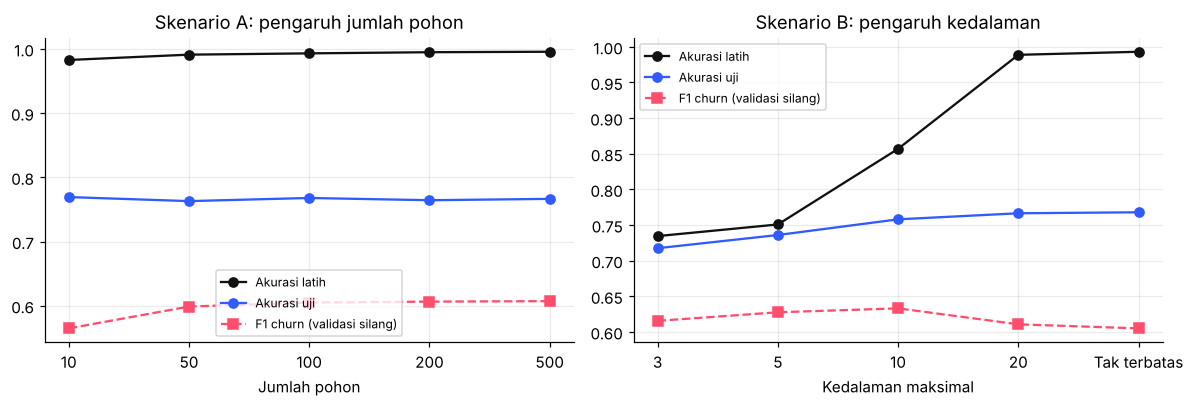

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))

x = range(len(tabel_a))
ax[0].plot(x, tabel_a["train_acc"], "o-", color=INK, label="Akurasi latih")
ax[0].plot(x, tabel_a["test_acc"], "o-", color=BLUE, label="Akurasi uji")
ax[0].plot(x, tabel_a["cv_f1"], "s--", color=RED, label="F1 churn (validasi silang)")
ax[0].set_xticks(list(x), tabel_a.index)
ax[0].set_xlabel("Jumlah pohon")
ax[0].set_title("Skenario A: pengaruh jumlah pohon")
ax[0].legend(fontsize=8)

x = range(len(tabel_b))
ax[1].plot(x, tabel_b["train_acc"], "o-", color=INK, label="Akurasi latih")
ax[1].plot(x, tabel_b["test_acc"], "o-", color=BLUE, label="Akurasi uji")
ax[1].plot(x, tabel_b["cv_f1"], "s--", color=RED, label="F1 churn (validasi silang)")
ax[1].set_xticks(list(x), tabel_b.index)
ax[1].set_xlabel("Kedalaman maksimal")
ax[1].set_title("Skenario B: pengaruh kedalaman")
ax[1].legend(fontsize=8)

plt.tight_layout()
plt.show()

**Cara membaca grafik:** garis hitam (latih) yang terus naik sementara garis biru (uji) mendatar adalah tanda *overfitting*. Di Skenario A, menambah pohon hampir tidak mengubah akurasi uji. Di Skenario B, selisih latih dan uji melebar tajam setelah kedalaman 10.

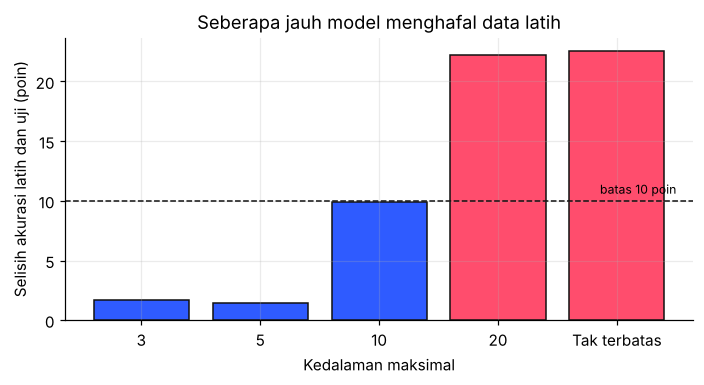

In [10]:
fig, ax = plt.subplots(figsize=(6.5, 3.6))
selisih = tabel_b["selisih_latih_uji"] * 100
warna = [RED if v > 10 else BLUE for v in selisih]
ax.bar([str(i) for i in tabel_b.index], selisih, color=warna, edgecolor=INK)
ax.axhline(10, color=INK, linestyle="--", linewidth=1)
ax.text(len(selisih) - 0.5, 10.6, "batas 10 poin", ha="right", fontsize=8)
ax.set_xlabel("Kedalaman maksimal")
ax.set_ylabel("Selisih akurasi latih dan uji (poin)")
ax.set_title("Seberapa jauh model menghafal data latih")
plt.tight_layout()
plt.show()

## 6. Model akhir dan evaluasi di data uji

Model dilatih ulang dengan konfigurasi terpilih. Data uji baru dipakai di sini untuk laporan akhir.

In [11]:
model = buat_model(n_terpilih, depth_terpilih).fit(X_train, y_train)
pred = model.predict(X_test)
proba = model.predict_proba(X_test)[:, 1]

print(f"Konfigurasi akhir: {n_terpilih} pohon, kedalaman maksimal {depth_terpilih}\n")
print(classification_report(y_test, pred, target_names=["Bertahan", "Churn"], digits=4))
print(f"AUC: {roc_auc_score(y_test, proba):.4f}")

Konfigurasi akhir: 100 pohon, kedalaman maksimal 10

              precision    recall  f1-score   support

    Bertahan     0.8970    0.7575    0.8214      1035
       Churn     0.5308    0.7594    0.6249       374

    accuracy                         0.7580      1409
   macro avg     0.7139    0.7584    0.7231      1409
weighted avg     0.7998    0.7580    0.7692      1409

AUC: 0.8377


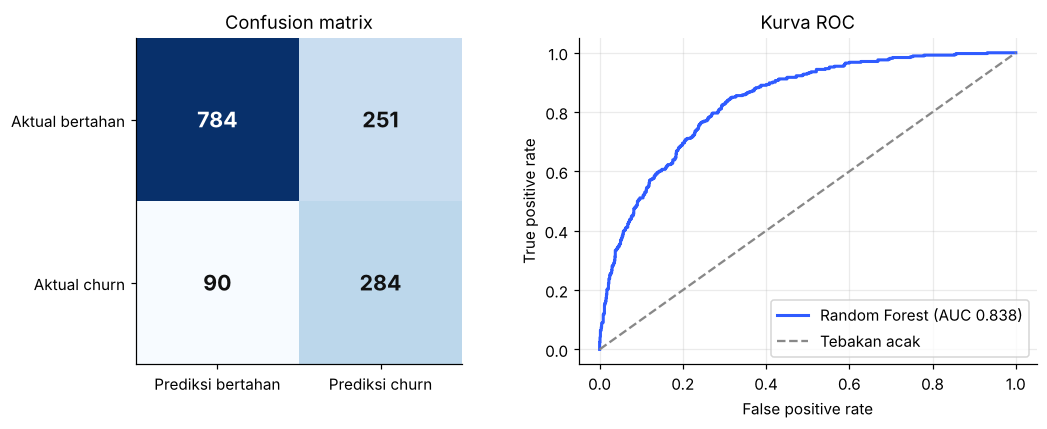

In [12]:
cm = confusion_matrix(y_test, pred)
fpr, tpr, _ = roc_curve(y_test, proba)

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].imshow(cm, cmap="Blues")
for i in range(2):
    for j in range(2):
        ax[0].text(j, i, f"{cm[i, j]:,}".replace(",", "."), ha="center", va="center",
                   fontsize=14, fontweight="bold", color="white" if cm[i, j] > cm.max() / 2 else INK)
ax[0].set_xticks([0, 1], ["Prediksi bertahan", "Prediksi churn"])
ax[0].set_yticks([0, 1], ["Aktual bertahan", "Aktual churn"])
ax[0].set_title("Confusion matrix")
ax[0].grid(False)

ax[1].plot(fpr, tpr, color=BLUE, linewidth=2, label=f"Random Forest (AUC {roc_auc_score(y_test, proba):.3f})")
ax[1].plot([0, 1], [0, 1], "--", color="#888", label="Tebakan acak")
ax[1].set_xlabel("False positive rate")
ax[1].set_ylabel("True positive rate")
ax[1].set_title("Kurva ROC")
ax[1].legend(loc="lower right")

plt.tight_layout()
plt.show()

## 7. Visualisasi feature importance

*Feature importance* di Random Forest menunjukkan seberapa besar tiap fitur menurunkan ketidakmurnian (Gini) saat dipakai untuk memecah data, dirata-rata dari semua pohon. Fitur kategorikal sudah dipecah jadi kolom One-Hot, jadi nama kolomnya berbentuk `Fitur_Nilai`.

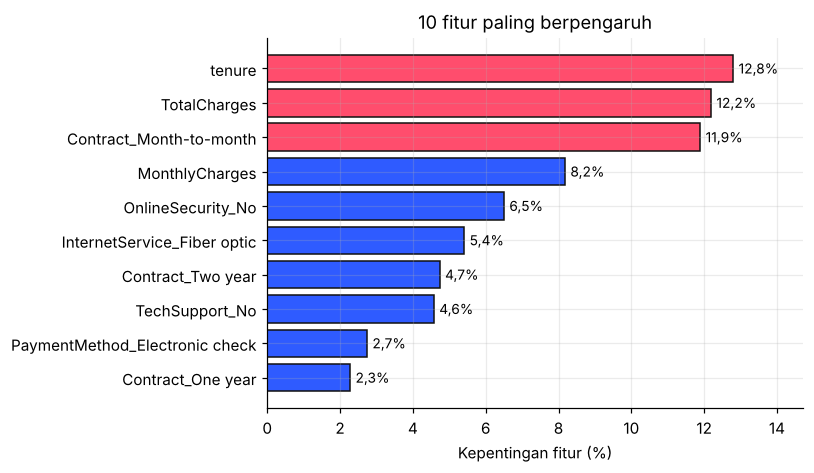

Tiga teratas menyumbang 36.9% dari seluruh kepentingan.
Sepuluh teratas menyumbang 71.3%.


In [13]:
nama = model.named_steps["prep"].get_feature_names_out()
penting = (
    pd.Series(model.named_steps["forest"].feature_importances_, index=nama)
    .sort_values(ascending=False)
)
top10 = penting.head(10)[::-1]

fig, ax = plt.subplots(figsize=(7.5, 4.4))
warna = [RED if i >= 7 else BLUE for i in range(10)]
ax.barh(top10.index, top10.values * 100, color=warna, edgecolor=INK)
for y_pos, v in enumerate(top10.values):
    ax.text(v * 100 + 0.15, y_pos, f"{v:.1%}".replace(".", ","), va="center", fontsize=9)
ax.set_xlabel("Kepentingan fitur (%)")
ax.set_title("10 fitur paling berpengaruh")
ax.set_xlim(0, top10.max() * 100 * 1.15)
plt.tight_layout()
plt.show()

print(f"Tiga teratas menyumbang {penting.head(3).sum():.1%} dari seluruh kepentingan.")
print(f"Sepuluh teratas menyumbang {penting.head(10).sum():.1%}.")

## 8. Ringkasan

In [14]:
rep = classification_report(y_test, pred, output_dict=True)
print(f"Konfigurasi terpilih : {n_terpilih} pohon, kedalaman {depth_terpilih}")
print(f"Akurasi uji          : {accuracy_score(y_test, pred):.1%}")
print(f"Recall churn         : {rep['1']['recall']:.1%}")
print(f"Precision churn      : {rep['1']['precision']:.1%}")
print(f"F1 churn             : {rep['1']['f1-score']:.4f}")
print(f"AUC                  : {roc_auc_score(y_test, proba):.4f}")

Konfigurasi terpilih : 100 pohon, kedalaman 10
Akurasi uji          : 75.8%
Recall churn         : 75.9%
Precision churn      : 53.1%
F1 churn             : 0.6249
AUC                  : 0.8377


**Catatan jujur:**

- Pembobotan kelas (`class_weight="balanced"`) membuat recall churn naik, tetapi akurasi dan precision turun. Ini pertukaran yang disengaja, karena kehilangan pelanggan umumnya lebih mahal daripada salah menawarkan program retensi.
- Skor model bukan probabilitas yang terkalibrasi, jadi 0,89 tidak berarti pelanggan pasti pergi.
- Data ini sampel fiktif dari IBM, jadi hasilnya cocok untuk belajar dan belum layak jadi dasar keputusan bisnis.